# Projet F5 — Facteurs de risque d'un portefeuille (Fama-French)

**Niveau :** maîtrise · **Langage :** Python (pandas, statsmodels, matplotlib) · **Durée indicative :** 2 semaines

Ce notebook suit la démarche en huit étapes des consignes pédagogiques communes :

| Étape | Contenu |
|---|---|
| 0 | Question précise et intérêt financier |
| 1 | Chargement des données, dimensions et variables |
| 2 | Nettoyage, analyse exploratoire, visualisations |
| 3 | Modèle de référence et modèles plus avancés |
| 4 | Protocole d'évaluation (chronologique) |
| 5 | Comparaison des métriques (R² ajusté, RMSE, MAE) |
| 6 | Limites : fuite, dérive temporelle, biais |
| 7 | Livrables : figures, tableaux, rapport synthétique (généré automatiquement) |

**Exécution :** `Exécution > Tout exécuter` dans Google Colab (connexion Internet requise au premier lancement ; les données sont ensuite mises en cache dans `data/`).

> Projet pédagogique : les résultats ne doivent pas servir de base à des décisions d'investissement réelles.

## 0. Question de recherche et intérêt financier

**Question principale.** Sur la période étudiée, la rentabilité mensuelle en excès de l'ETF **IWM** (Russell 2000, petites capitalisations américaines) s'explique-t-elle par le seul risque de marché (CAPM), ou faut-il y ajouter les facteurs **taille (SMB)** et **valeur (HML)** du modèle de Fama-French à trois facteurs ? L'ETF produit-il un **alpha** significatif une fois ces expositions contrôlées ?

**Sous-questions.**
1. *Validation du modèle sur des portefeuilles dont l'exposition est connue :* SPY (marché large) devrait avoir β ≈ 1 et SMB ≈ HML ≈ 0 ; IWM devrait avoir SMB > 0 ; IWD (valeur) devrait avoir HML > 0 ; IWF (croissance) devrait avoir HML < 0.
2. *Stabilité :* les expositions sont-elles constantes dans le temps ?
3. *Pouvoir explicatif hors échantillon :* le modèle à trois facteurs réduit-il l'erreur par rapport au CAPM et à une simple moyenne, en estimant sur le passé uniquement ?

**Hypothèse nulle sur l'alpha :** α = 0 (aucune performance anormale après prise en compte des expositions aux facteurs).

**Intérêt financier.**
- *Attribution de performance :* séparer ce qui vient d'expositions rémunérées (marché, taille, valeur), reproductibles à faible coût, de ce qui relèverait d'une compétence (alpha).
- *Évaluation de gérants et de fonds :* un fonds qui « bat le marché » en surpondérant les petites valeurs n'a pas nécessairement de compétence.
- *Gestion des risques et allocation :* les bêtas aux facteurs mesurent à quels risques systématiques le portefeuille est réellement exposé.
- *Coût du capital :* le modèle fournit une estimation du rendement exigé selon les expositions.

In [43]:
import os, re, io, sys, zipfile, urllib.request, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.regression.rolling import RollingOLS
from scipy import stats

try:
    import yfinance as yf
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "yfinance"])
    import yfinance as yf

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---- Paramètres modifiables -------------------------------------------------
TICKERS = {                      # portefeuilles étudiés (ETF) et leur style attendu
    "SPY": "S&P 500 (marché large)",
    "IWM": "Russell 2000 (petites capitalisations)",
    "IWD": "Russell 1000 Value (valeur)",
    "IWF": "Russell 1000 Growth (croissance)",
}
MAIN = "IWM"          # portefeuille principal analysé en détail
START = "2001-01-01"  # début de la période de téléchargement des cours
HAC_LAGS = 6          # décalages pour les erreurs standard robustes (Newey-West)
ROLL = 36             # fenêtre (mois) des régressions glissantes
MIN_TRAIN = 60        # taille minimale d'apprentissage (mois) pour l'évaluation hors échantillon
SIGNIF = 0.05

URL_FF3 = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip"
URL_FF5 = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_CSV.zip"
DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

## 1. Chargement des données

**Source 1 — facteurs Fama-French (mensuels)** : bibliothèque de données de Kenneth French. Le fichier contient `Mkt-RF` (rendement du marché moins taux sans risque), `SMB` (petites moins grandes capitalisations), `HML` (valeur moins croissance) et `RF` (taux sans risque). Les valeurs sont en **pourcentage** ; le fichier contient en bas une section annuelle à exclure, et le code `-99.99` désigne une valeur manquante.

**Source 2 — cours des ETF** : Yahoo Finance via `yfinance` (cours ajustés des dividendes). Ce n'est pas une API officielle : elle peut changer sans préavis, d'où la mise en cache locale.

In [44]:
UA = {"User-Agent": "Mozilla/5.0"}

def download(url, path):
    """Télécharge un fichier une seule fois (cache local)."""
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers=UA)
        with urllib.request.urlopen(req, timeout=60) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

def read_french_monthly(zip_path):
    """Lit la partie MENSUELLE d'un fichier zip Ken French. Retourne des décimaux (pas des %)."""
    with zipfile.ZipFile(zip_path) as z:
        text = z.read(z.namelist()[0]).decode("latin-1")
    lines = text.splitlines()
    h = next(i for i, l in enumerate(lines) if "Mkt-RF" in l)
    cols = [c.strip() for c in lines[h].split(",")[1:]]
    rows = []
    for l in lines[h + 1:]:
        p = [x.strip() for x in l.split(",")]
        if re.fullmatch(r"\d{6}", p[0]):          # ligne mensuelle AAAAMM
            rows.append(p[:len(cols) + 1])
        elif rows:                                # fin du bloc mensuel : on s'arrête
            break
    df = pd.DataFrame(rows, columns=["date"] + cols)
    df.index = pd.PeriodIndex(pd.to_datetime(df.pop("date"), format="%Y%m"), freq="M", name="date")
    df = df.astype(float).replace([-99.99, -999.0], np.nan)
    return df / 100.0

ff3 = read_french_monthly(download(URL_FF3, os.path.join(DATA_DIR, "F-F_Research_Data_Factors_CSV.zip")))

print("Facteurs Fama-French (mensuel, en décimal)")
print("  Dimensions :", ff3.shape, "| période :", ff3.index.min(), "→", ff3.index.max())
print("  Variables  :", list(ff3.columns))
print("  Valeurs manquantes :", int(ff3.isna().sum().sum()))
ff3.head()

Facteurs Fama-French (mensuel, en décimal)
  Dimensions : (1203, 4) | période : 1926-07 → 2026-09
  Variables  : ['Mkt-RF', 'SMB', 'HML', 'RF']
  Valeurs manquantes : 0


,Mkt-RF,SMB,HML,RF
date,,,,
1926-07,0.0289,-0.0242,-0.0275,0.0022
1926-08,0.0264,-0.0144,0.0413,0.0025
1926-09,0.0038,-0.0136,0.0005,0.0023
1926-10,-0.0327,-0.0018,0.0078,0.0032
1926-11,0.0254,-0.0017,-0.0048,0.0031


In [45]:
PRICE_CACHE = os.path.join(DATA_DIR, "prices_monthly.csv")

def load_monthly_prices(tickers, start):
    """Cours ajustés, dernier cours de chaque mois, mois en cours exclu s'il est incomplet."""
    if os.path.exists(PRICE_CACHE):
        px = pd.read_csv(PRICE_CACHE, index_col=0)
        px.index = pd.PeriodIndex(px.index, freq="M", name="date")
        if set(tickers).issubset(px.columns):
            return px[list(tickers)]
    raw = yf.download(list(tickers), start=start, auto_adjust=True, progress=False)["Close"]
    raw = raw[list(tickers)].dropna(how="all")
    px = raw.groupby(raw.index.to_period("M")).last()
    px.index.name = "date"
    if px.index[-1] == pd.Period(pd.Timestamp.today(), freq="M"):   # mois non terminé
        px = px.iloc[:-1]
    px.to_csv(PRICE_CACHE)
    return px

prices = load_monthly_prices(TICKERS.keys(), START)
print("Cours mensuels ajustés")
print("  Dimensions :", prices.shape, "| période :", prices.index.min(), "→", prices.index.max())
print("  Valeurs manquantes par ETF :\n", prices.isna().sum().to_string())
prices.tail()

Cours mensuels ajustés
  Dimensions : (310, 4) | période : 2001-01 → 2026-10
  Valeurs manquantes par ETF :
 SPY    0
IWM    0
IWD    0
IWF    0


,SPY,IWM,IWD,IWF
date,,,,
2026-06,744.9202,299.6674,241.5471,124.0584
2026-07,745.1796,290.4414,250.9029,118.2136
2026-08,765.1500,293.1643,255.9744,122.5997
2026-09,762.6300,277.8900,247.9300,125.2600
2026-10,755.7200,279.3300,258.6500,117.6100


## 2. Nettoyage, alignement et analyse exploratoire

Étapes : (i) rendements mensuels simples à partir des cours ajustés ; (ii) échantillon commun à tous les ETF et aux facteurs ; (iii) rendements **en excès** du taux sans risque (`R_ex = R − RF`) ; (iv) contrôle des unités (tout en décimal) et des valeurs extrêmes.

In [46]:
ret = prices.pct_change().dropna()                 # rendements mensuels, décimal, index en périodes
data = ff3.join(ret, how="inner").dropna()         # intersection des dates
data.index = data.index.to_timestamp()             # index temporel pour les graphiques
for t in TICKERS:
    data[f"{t}_ex"] = data[t] - data["RF"]         # rendement en excès

FACTORS = ["Mkt-RF", "SMB", "HML"]
EXCESS = [f"{t}_ex" for t in TICKERS]

print(f"Échantillon commun : {len(data)} mois, de {data.index.min():%Y-%m} à {data.index.max():%Y-%m}")
print("Valeurs manquantes :", int(data.isna().sum().sum()))

# contrôle de cohérence des unités : un rendement mensuel dépasse rarement ±30 % en décimal
assert data[FACTORS + EXCESS].abs().max().max() < 0.6, "Unités suspectes : mélange % / décimal ?"

# valeurs extrêmes (|z| > 4)
z = (data[FACTORS + EXCESS] - data[FACTORS + EXCESS].mean()) / data[FACTORS + EXCESS].std()
print("Observations avec |z| > 4 :\n", (z.abs() > 4).sum().to_string())

# statistiques descriptives annualisées
desc = pd.DataFrame({
    "Moyenne ann. (%)": data[FACTORS + EXCESS].mean() * 12 * 100,
    "Vol. ann. (%)": data[FACTORS + EXCESS].std() * np.sqrt(12) * 100,
})
desc["Ratio de Sharpe"] = desc["Moyenne ann. (%)"] / desc["Vol. ann. (%)"]
desc

Échantillon commun : 308 mois, de 2001-02 à 2026-09
Valeurs manquantes : 0
Observations avec |z| > 4 :
 Mkt-RF    0
SMB       0
HML       2
SPY_ex    0
IWM_ex    0
IWD_ex    2
IWF_ex    0


,Moyenne ann. (%),Vol. ann. (%),Ratio de Sharpe
Mkt-RF,8.3225,15.5295,0.5359
SMB,1.0827,8.9825,0.1205
HML,1.2990,10.9930,0.1182
SPY_ex,7.9058,15.0742,0.5245
IWM_ex,8.2298,19.9532,0.4125
IWD_ex,7.2051,15.1974,0.4741
IWF_ex,8.4968,17.0314,0.4989


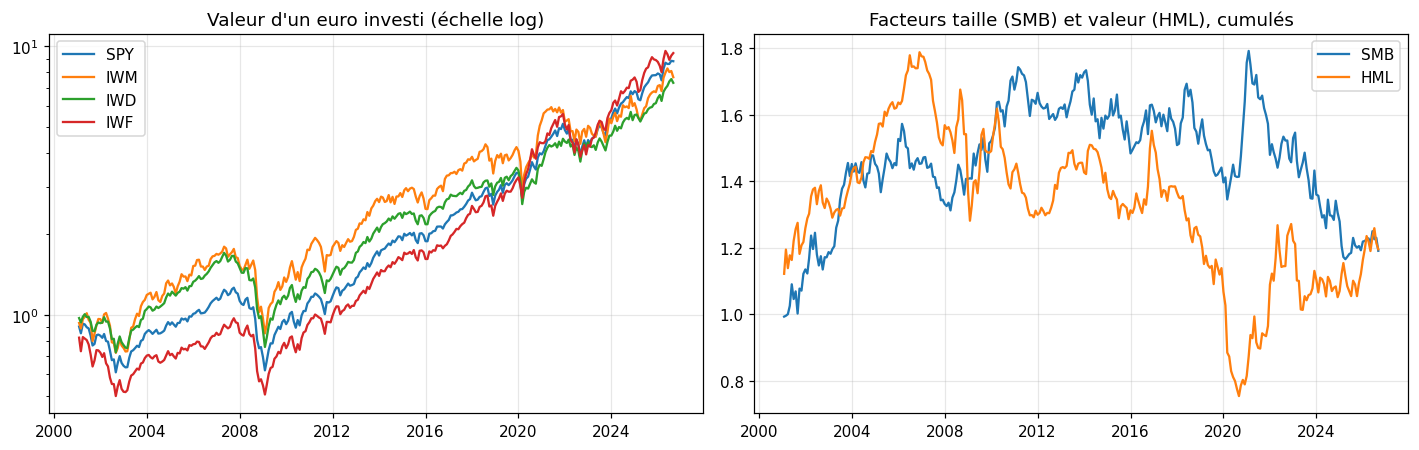

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
growth = (1 + data[list(TICKERS)]).cumprod()
for t in TICKERS:
    axes[0].plot(growth.index, growth[t], label=t)
axes[0].set_yscale("log"); axes[0].set_title("Valeur d'un euro investi (échelle log)"); axes[0].legend()
fgrowth = (1 + data[["SMB", "HML"]]).cumprod()
for c in fgrowth:
    axes[1].plot(fgrowth.index, fgrowth[c], label=c)
axes[1].set_title("Facteurs taille (SMB) et valeur (HML), cumulés"); axes[1].legend()
plt.tight_layout(); savefig("fig1_performance_cumulee.png"); plt.show()

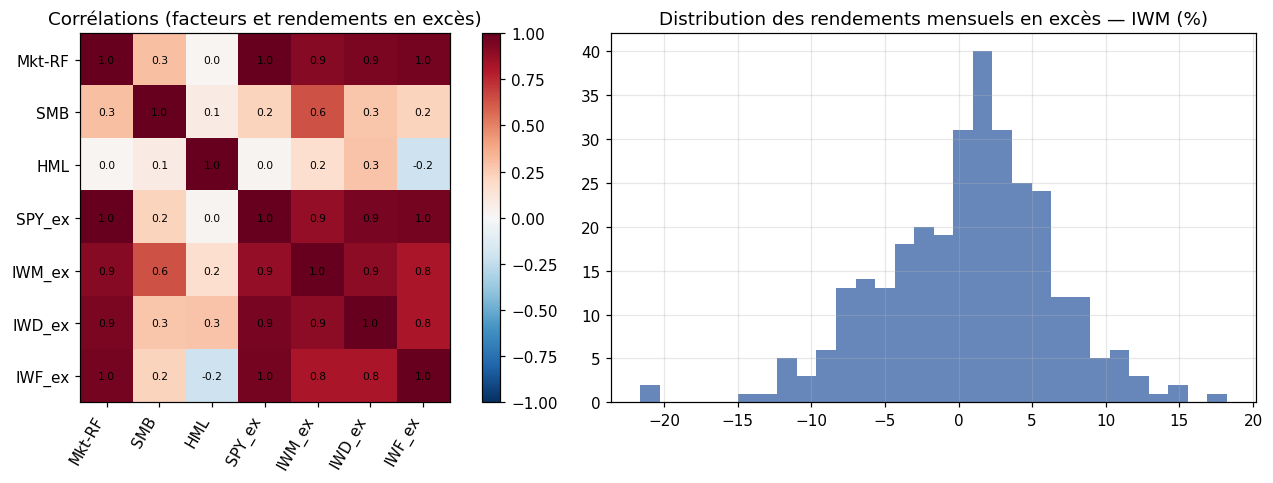

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cols = FACTORS + EXCESS
corr = data[cols].corr()
im = axes[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(cols))); axes[0].set_xticklabels(cols, rotation=60, ha="right")
axes[0].set_yticks(range(len(cols))); axes[0].set_yticklabels(cols); axes[0].grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        axes[0].text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
axes[0].set_title("Corrélations (facteurs et rendements en excès)")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(data[f"{MAIN}_ex"] * 100, bins=30, color="#4C72B0", alpha=0.85)
axes[1].set_title(f"Distribution des rendements mensuels en excès — {MAIN} (%)")
plt.tight_layout(); savefig("fig2_correlations_distribution.png"); plt.show()

**À observer :** corrélation très élevée entre `SPY_ex` et `Mkt-RF` (le marché explique l'essentiel de la variance) ; corrélations entre facteurs modérées (important pour la colinéarité, vérifiée plus loin par les VIF).

## 3. Modèles : référence et modèles plus avancés

Pour chaque ETF, régression des rendements en excès sur les facteurs, par MCO avec **erreurs standard robustes HAC (Newey-West)** :

| Modèle | Spécification | Rôle |
|---|---|---|
| Moyenne (réf.) | `R_ex = α + ε` | Référence minimale : aucun facteur |
| CAPM | `R_ex = α + β·(Mkt-RF) + ε` | Modèle à un facteur |
| FF3 | `R_ex = α + β·(Mkt-RF) + s·SMB + h·HML + ε` | Modèle plus avancé |

Une extension à cinq facteurs (FF5 : ajout de profitabilité RMW et investissement CMA) est testée plus bas.

In [49]:
MODELS = {
    "Moyenne (réf.)": [],
    "CAPM": ["Mkt-RF"],
    "FF3": ["Mkt-RF", "SMB", "HML"],
}

def design(df, xs):
    X = df[list(xs)].copy() if xs else pd.DataFrame(index=df.index)
    X.insert(0, "const", 1.0)
    return X

def fit_ols(df, y, xs, robust=True):
    m = sm.OLS(df[y], design(df, xs))
    return m.fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}) if robust else m.fit()

def joint_p(res, hypothesis):
    try:
        w = res.wald_test(hypothesis, use_f=True, scalar=True)
    except TypeError:
        w = res.wald_test(hypothesis, use_f=True)
    return float(np.squeeze(w.pvalue))

RES, rows = {}, []
for t in TICKERS:
    for m, xs in MODELS.items():
        r = fit_ols(data, f"{t}_ex", xs)
        RES[(t, m)] = r
        ci = r.conf_int().loc["const"]
        rows.append({
            "ETF": t, "Modèle": m, "N": int(r.nobs),
            "alpha (%/mois)": 100 * r.params["const"],
            "IC95 bas": 100 * ci.iloc[0], "IC95 haut": 100 * ci.iloc[1],
            "t(alpha)": r.tvalues["const"], "p(alpha)": r.pvalues["const"],
            "R² ajusté": r.rsquared_adj,
        })
tab_models = pd.DataFrame(rows)
tab_models

,ETF,Modèle,N,alpha (%/mois),IC95 bas,IC95 haut,t(alpha),p(alpha),R² ajusté
0,SPY,Moyenne (réf.),308,0.6588,0.1578,1.1598,2.5773,0.0100,0.0000
1,SPY,CAPM,308,-0.0108,-0.0617,0.0400,-0.4167,0.6769,0.9894
2,SPY,FF3,308,-0.0163,-0.0448,0.0122,-1.1233,0.2613,0.9956
3,IWM,Moyenne (réf.),308,0.6858,0.0646,1.3071,2.1637,0.0305,-0.0000
4,IWM,CAPM,308,-0.1239,-0.3926,0.1449,-0.9032,0.3664,0.8250
5,IWM,FF3,308,-0.1198,-0.2033,-0.0364,-2.8141,0.0049,0.9841
6,IWD,Moyenne (réf.),308,0.6004,0.0944,1.1065,2.3254,0.0200,-0.0000
7,IWD,CAPM,308,-0.0398,-0.2407,0.1611,-0.3883,0.6978,0.8894
8,IWD,FF3,308,-0.0771,-0.1711,0.0169,-1.6075,0.1079,0.9592
9,IWF,Moyenne (réf.),308,0.7081,0.1328,1.2833,2.4124,0.0158,0.0000


In [50]:
# Coefficients du modèle FF3 pour chaque ETF, avec intervalles de confiance à 95 %
rows = []
for t in TICKERS:
    r = RES[(t, "FF3")]
    ci = r.conf_int()
    row = {"ETF": t, "Style": TICKERS[t]}
    for k in ["const"] + FACTORS:
        name = "alpha (%/mois)" if k == "const" else k
        scale = 100 if k == "const" else 1
        row[name] = scale * r.params[k]
        row[name + " p"] = r.pvalues[k]
    row["R² ajusté"] = r.rsquared_adj
    row["Test conjoint SMB=HML=0 (p)"] = joint_p(r, "SMB = 0, HML = 0")
    rows.append(row)
tab_ff3 = pd.DataFrame(rows).set_index("ETF")
tab_ff3

,Style,alpha (%/mois),alpha (%/mois) p,Mkt-RF,Mkt-RF p,SMB,SMB p,HML,HML p,R² ajusté,Test conjoint SMB=HML=0 (p)
ETF,,,,,,,,,,,
SPY,S&P 500 (marché large),-0.0163,0.2613,0.9892,0.0000,-0.1388,0.0000,0.0149,0.0042,0.9956,0.0000
IWM,Russell 2000 (petites capitalisations),-0.1198,0.0049,1.0155,0.0000,0.8631,0.0000,0.2167,0.0000,0.9841,0.0000
IWD,Russell 1000 Value (valeur),-0.0771,0.1079,0.9262,0.0000,-0.0495,0.0137,0.3661,0.0000,0.9592,0.0000
IWF,Russell 1000 Growth (croissance),0.0102,0.8142,1.0740,0.0000,-0.1042,0.0000,-0.3476,0.0000,0.9728,0.0000


In [51]:
# Résumé détaillé du portefeuille principal
print(RES[(MAIN, "FF3")].summary())

                            OLS Regression Results                            
Dep. Variable:                 IWM_ex   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.984
Method:                 Least Squares   F-statistic:                     5312.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          3.36e-262
Time:                        23:55:54   Log-Likelihood:                 1081.8
No. Observations:                 308   AIC:                            -2156.
Df Residuals:                     304   BIC:                            -2141.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0012      0.000     -2.814      0.0

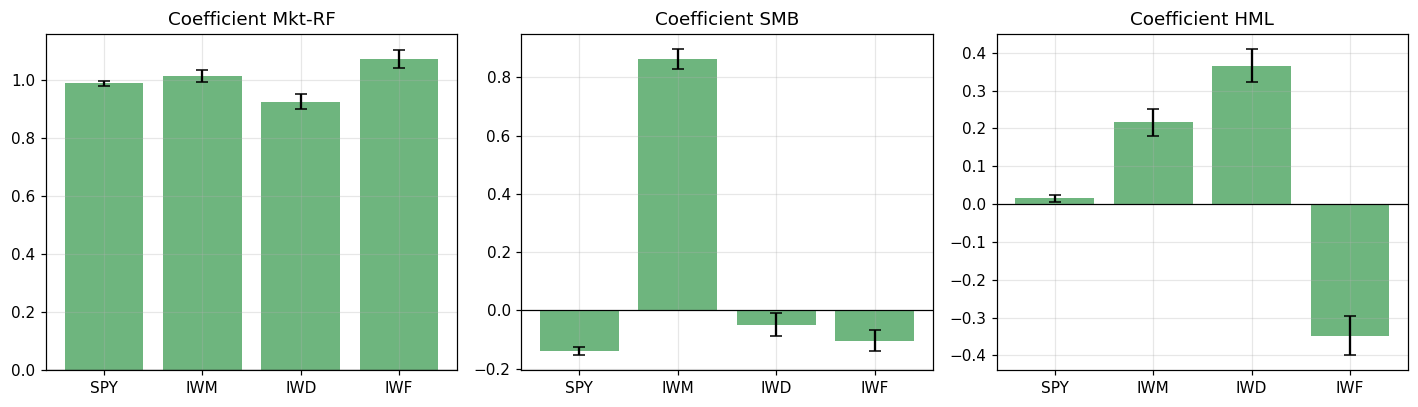

In [52]:
# Figure : exposition aux facteurs (coefficients FF3 et IC95 %) par ETF
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, f in zip(axes, FACTORS):
    est = [RES[(t, "FF3")].params[f] for t in TICKERS]
    ci = [RES[(t, "FF3")].conf_int().loc[f].values for t in TICKERS]
    err = np.array([[e - c[0], c[1] - e] for e, c in zip(est, ci)]).T
    ax.bar(list(TICKERS), est, yerr=err, capsize=4, color="#55A868", alpha=0.85)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"Coefficient {f}")
plt.tight_layout(); savefig("fig3_coefficients_ff3.png"); plt.show()

In [53]:
# Extension : modèle à cinq facteurs (FF5), sur l'échantillon commun avec ses propres facteurs
tab_ff5 = None
try:
    ff5 = read_french_monthly(download(URL_FF5, os.path.join(DATA_DIR, "F-F_Research_Data_5_Factors_2x3_CSV.zip")))
    d5 = ff5.join(ret, how="inner").dropna()
    d5.index = d5.index.to_timestamp()
    for t in TICKERS:
        d5[f"{t}_ex"] = d5[t] - d5["RF"]
    FF5 = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
    rows = []
    for t in TICKERS:
        r3 = fit_ols(d5, f"{t}_ex", MODELS["FF3"])
        r5 = fit_ols(d5, f"{t}_ex", FF5)
        rows.append({"ETF": t, "R² aj. FF3": r3.rsquared_adj, "R² aj. FF5": r5.rsquared_adj,
                     "alpha FF3 (%/mois)": 100 * r3.params["const"],
                     "alpha FF5 (%/mois)": 100 * r5.params["const"], "p(alpha) FF5": r5.pvalues["const"]})
    tab_ff5 = pd.DataFrame(rows).set_index("ETF")
except Exception as e:
    print("Extension FF5 non exécutée :", repr(e))
tab_ff5

,R² aj. FF3,R² aj. FF5,alpha FF3 (%/mois),alpha FF5 (%/mois),p(alpha) FF5
ETF,,,,,
SPY,0.9955,0.9958,-0.0147,-0.0324,0.0217
IWM,0.9867,0.9881,-0.1328,-0.0877,0.0092
IWD,0.9587,0.9619,-0.0763,-0.1258,0.0057
IWF,0.9740,0.9759,0.0109,0.0509,0.1774


## 4. Protocole d'évaluation : chronologique, sans fuite d'information

Un découpage aléatoire est à proscrire sur des séries temporelles. On utilise une **fenêtre extensible** : pour chaque mois *t* à partir de `MIN_TRAIN`, les coefficients sont estimés **uniquement sur les mois antérieurs à t**, puis appliqués aux facteurs observés au mois *t*.

*Précision importante :* il s'agit d'une évaluation « en direct » (nowcast) : les facteurs du mois *t* sont supposés connus, comme dans toute régression d'attribution. Ce n'est pas une prévision du rendement avant sa réalisation. L'intérêt est de vérifier que la relation estimée **généralise dans le temps** et n'est pas un artefact de l'échantillon.

La référence est la **moyenne historique** du rendement en excès, estimée sur le même passé.

In [54]:
def expanding_forecast(df, y, xs, min_train):
    preds, idx = [], []
    for t in range(min_train, len(df)):
        tr, te = df.iloc[:t], df.iloc[t:t + 1]
        b = np.linalg.lstsq(design(tr, xs).values, tr[y].values, rcond=None)[0]
        preds.append(float((design(te, xs).values @ b)[0])); idx.append(df.index[t])
    return pd.Series(preds, index=idx)

OOS, FCST = {}, {}
for t in TICKERS:
    y = f"{t}_ex"
    base = expanding_forecast(data, y, MODELS["Moyenne (réf.)"], MIN_TRAIN)
    actual = data[y].loc[base.index]
    sse_base = float(((actual - base) ** 2).sum())
    for m, xs in MODELS.items():
        p = base if m == "Moyenne (réf.)" else expanding_forecast(data, y, xs, MIN_TRAIN)
        e = actual - p
        FCST[(t, m)] = p
        OOS[(t, m)] = {"RMSE (%)": 100 * float(np.sqrt((e ** 2).mean())),
                       "MAE (%)": 100 * float(e.abs().mean()),
                       "R² hors éch.": 1 - float((e ** 2).sum()) / sse_base}

tab_oos = (pd.DataFrame(OOS).T.rename_axis(["ETF", "Modèle"]).reset_index())
print(f"Évaluation sur {len(base)} mois (de {base.index.min():%Y-%m} à {base.index.max():%Y-%m})")
tab_oos

Évaluation sur 248 mois (de 2006-02 à 2026-09)


,ETF,Modèle,RMSE (%),MAE (%),R² hors éch.
0,SPY,Moyenne (réf.),4.3749,3.3523,0.0000
1,SPY,CAPM,0.4247,0.3300,0.9906
2,SPY,FF3,0.2643,0.1980,0.9963
3,IWM,Moyenne (réf.),5.7945,4.4175,0.0000
4,IWM,CAPM,2.3509,1.8158,0.8354
5,IWM,FF3,0.7250,0.5496,0.9843
6,IWD,Moyenne (réf.),4.5005,3.3999,0.0000
7,IWD,CAPM,1.4986,1.0816,0.8891
8,IWD,FF3,0.9031,0.6716,0.9597
9,IWF,Moyenne (réf.),4.8155,3.7588,0.0000


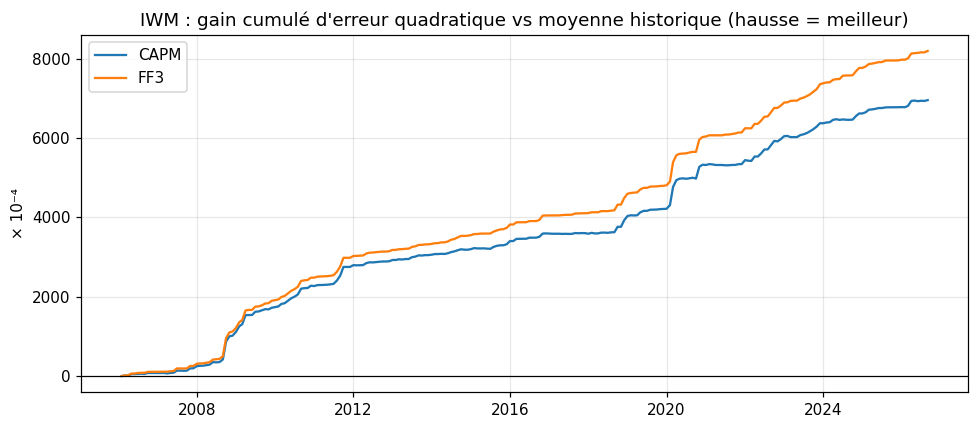

In [55]:
# Erreur quadratique cumulée économisée par rapport à la moyenne historique (portefeuille principal)
y = f"{MAIN}_ex"
actual = data[y].loc[FCST[(MAIN, "CAPM")].index]
fig, ax = plt.subplots(figsize=(9, 4))
for m in ["CAPM", "FF3"]:
    gain = ((actual - FCST[(MAIN, "Moyenne (réf.)")]) ** 2 - (actual - FCST[(MAIN, m)]) ** 2).cumsum()
    ax.plot(gain.index, gain * 1e4, label=m)
ax.axhline(0, color="k", lw=0.8)
ax.set_title(f"{MAIN} : gain cumulé d'erreur quadratique vs moyenne historique (hausse = meilleur)")
ax.set_ylabel("× 10⁻⁴"); ax.legend()
plt.tight_layout(); savefig("fig4_gain_hors_echantillon.png"); plt.show()

## 5. Comparaison des métriques

Régression : on compare le **R² ajusté** (en échantillon, pénalise le nombre de facteurs), puis **RMSE, MAE et R² hors échantillon** (par rapport à la moyenne historique). Un R² hors échantillon positif signifie que le modèle fait mieux que la simple moyenne.

In [56]:
comp = (tab_models.merge(tab_oos, on=["ETF", "Modèle"])
        [["ETF", "Modèle", "R² ajusté", "RMSE (%)", "MAE (%)", "R² hors éch."]])
comp_pivot = comp.pivot(index="ETF", columns="Modèle")
comp

,ETF,Modèle,R² ajusté,RMSE (%),MAE (%),R² hors éch.
0,SPY,Moyenne (réf.),0.0000,4.3749,3.3523,0.0000
1,SPY,CAPM,0.9894,0.4247,0.3300,0.9906
2,SPY,FF3,0.9956,0.2643,0.1980,0.9963
3,IWM,Moyenne (réf.),-0.0000,5.7945,4.4175,0.0000
4,IWM,CAPM,0.8250,2.3509,1.8158,0.8354
5,IWM,FF3,0.9841,0.7250,0.5496,0.9843
6,IWD,Moyenne (réf.),-0.0000,4.5005,3.3999,0.0000
7,IWD,CAPM,0.8894,1.4986,1.0816,0.8891
8,IWD,FF3,0.9592,0.9031,0.6716,0.9597
9,IWF,Moyenne (réf.),0.0000,4.8155,3.7588,0.0000


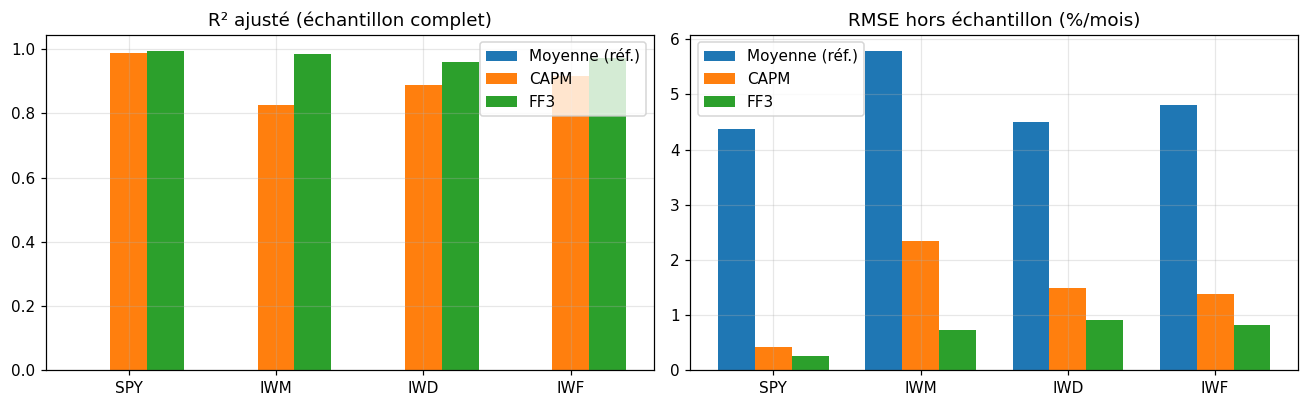

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.25
x = np.arange(len(TICKERS))
for k, m in enumerate(MODELS):
    sub = comp[comp["Modèle"] == m].set_index("ETF").loc[list(TICKERS)]
    axes[0].bar(x + (k - 1) * w, sub["R² ajusté"], w, label=m)
    axes[1].bar(x + (k - 1) * w, sub["RMSE (%)"], w, label=m)
for ax, ttl in zip(axes, ["R² ajusté (échantillon complet)", "RMSE hors échantillon (%/mois)"]):
    ax.set_xticks(x); ax.set_xticklabels(list(TICKERS)); ax.set_title(ttl); ax.legend()
plt.tight_layout(); savefig("fig5_comparaison_modeles.png"); plt.show()

## 6. Diagnostics, stabilité et limites

### 6.1 Diagnostics des résidus (portefeuille principal, modèle FF3)

In [58]:
y = f"{MAIN}_ex"
r0 = fit_ols(data, y, MODELS["FF3"], robust=False)    # MCO classique pour les tests
X = design(data, MODELS["FF3"])
diag = {
    "Durbin-Watson (≈2 : pas d'autocorrélation)": float(durbin_watson(r0.resid)),
    "Breusch-Pagan, p-valeur (H0 : homoscédasticité)": float(het_breuschpagan(r0.resid, r0.model.exog)[1]),
    "Jarque-Bera, p-valeur (H0 : normalité)": float(jarque_bera(r0.resid)[1]),
}
for i, c in enumerate(X.columns[1:], start=1):
    diag[f"VIF {c} (>5 : colinéarité préoccupante)"] = float(variance_inflation_factor(X.values, i))
pd.Series(diag, name=MAIN).to_frame()

,IWM
Durbin-Watson (≈2 : pas d'autocorrélation),2.0233
"Breusch-Pagan, p-valeur (H0 : homoscédasticité)",0.8780
"Jarque-Bera, p-valeur (H0 : normalité)",0.1653
VIF Mkt-RF (>5 : colinéarité préoccupante),1.0973
VIF SMB (>5 : colinéarité préoccupante),1.1039
VIF HML (>5 : colinéarité préoccupante),1.0064


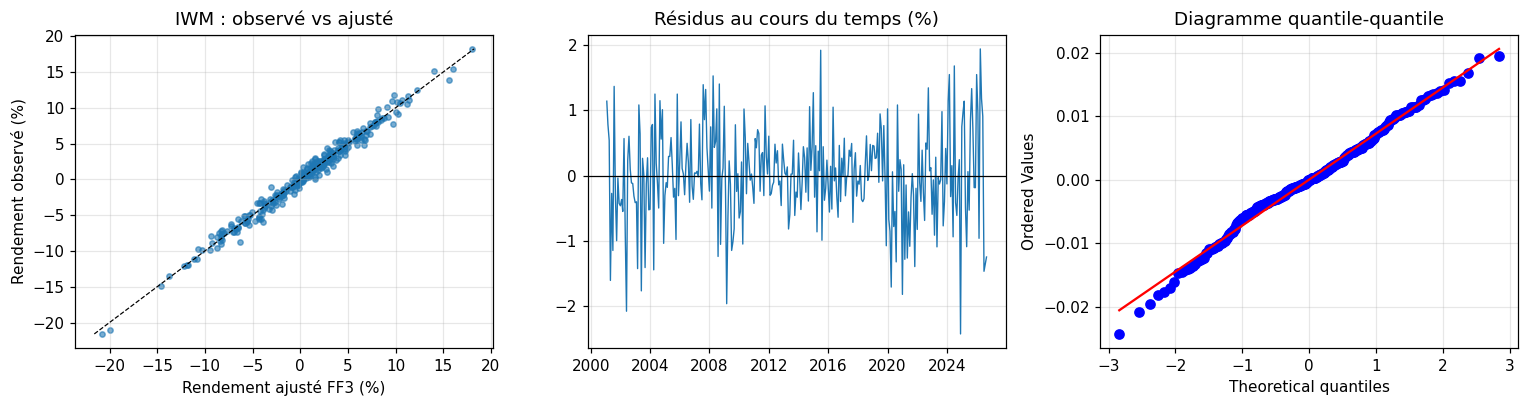

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
fitted = r0.fittedvalues * 100
axes[0].scatter(fitted, data[y] * 100, s=12, alpha=0.6)
lim = [min(fitted.min(), (data[y] * 100).min()), max(fitted.max(), (data[y] * 100).max())]
axes[0].plot(lim, lim, "k--", lw=0.8)
axes[0].set_xlabel("Rendement ajusté FF3 (%)"); axes[0].set_ylabel("Rendement observé (%)")
axes[0].set_title(f"{MAIN} : observé vs ajusté")
axes[1].plot(r0.resid.index, r0.resid * 100, lw=0.9)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_title("Résidus au cours du temps (%)")
stats.probplot(r0.resid, dist="norm", plot=axes[2]); axes[2].set_title("Diagramme quantile-quantile")
plt.tight_layout(); savefig("fig6_diagnostics_residus.png"); plt.show()

### 6.2 Dérive temporelle : stabilité des bêtas

In [60]:
mid = len(data) // 2
rows = []
for label, sub in [("1ʳᵉ moitié", data.iloc[:mid]), ("2ᵉ moitié", data.iloc[mid:])]:
    r = fit_ols(sub, y, MODELS["FF3"])
    row = {"Sous-période": f"{label} ({sub.index.min():%Y-%m} → {sub.index.max():%Y-%m})", "N": int(r.nobs),
           "alpha (%/mois)": 100 * r.params["const"], "R² ajusté": r.rsquared_adj}
    for f in FACTORS:
        row[f] = r.params[f]
    rows.append(row)
tab_sub = pd.DataFrame(rows)
tab_sub

,Sous-période,N,alpha (%/mois),R² ajusté,Mkt-RF,SMB,HML
0,1ʳᵉ moitié (2001-02 → 2013-11),154,-0.1006,0.9857,1.0146,0.8562,0.1870
1,2ᵉ moitié (2013-12 → 2026-09),154,-0.1303,0.9824,1.0198,0.8657,0.2341


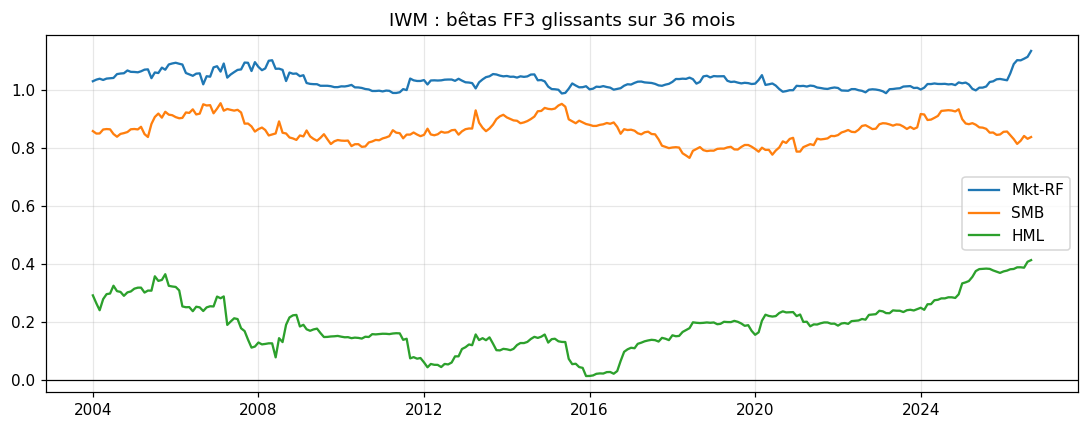

In [61]:
roll = RollingOLS(data[y], design(data, MODELS["FF3"]), window=ROLL).fit().params
fig, ax = plt.subplots(figsize=(10, 4))
for f in FACTORS:
    ax.plot(roll.index, roll[f], label=f)
ax.axhline(0, color="k", lw=0.8)
ax.set_title(f"{MAIN} : bêtas FF3 glissants sur {ROLL} mois"); ax.legend()
plt.tight_layout(); savefig("fig7_betas_glissants.png"); plt.show()

### 6.3 Limites de l'étude

- **Fuite de données / biais d'anticipation.** Les facteurs de Ken French sont publiés avec retard et parfois révisés ; l'évaluation hors échantillon n'utilise que le passé pour estimer les coefficients, mais les facteurs du mois courant y sont supposés connus (attribution, pas prévision).
- **Biais de survie.** Les ETF étudiés existent encore aujourd'hui. Étudier des fonds disparus donnerait probablement des alphas plus faibles. Un panier d'actions *actuelles* aggraverait ce biais.
- **Alpha et hasard.** Quatre ETF et plusieurs modèles sont testés : sans correction pour tests multiples, un alpha « significatif » peut être dû au hasard (*data snooping*). Un alpha estimé sur quelques centaines de mois a un intervalle de confiance large.
- **Dérive temporelle.** Les bêtas ne sont pas constants (cf. régressions glissantes et sous-périodes) : un seul jeu de coefficients résume mal vingt ans de vie d'un fonds dont la composition évolue.
- **Coûts et frais.** Les ETF ont des frais de gestion et un écart de réplication ; les facteurs de Ken French sont des portefeuilles théoriques sans coûts de transaction : une partie de l'alpha négatif éventuel est simplement ce coût.
- **Hypothèses des MCO.** Résidus non normaux et hétéroscédastiques sont fréquents en finance ; d'où les erreurs standard HAC. Les tests de diagnostic ci-dessus quantifient l'écart.
- **Représentativité.** Marché américain uniquement, ETF liquides et gros : les conclusions ne s'étendent pas à des fonds internationaux ni à des actions individuelles.
- **Causalité.** Un facteur qui « explique » un rendement décrit une exposition, pas une cause économique.

## 7. Livrables : tableaux et rapport synthétique

La cellule suivante exporte les tableaux (`resultats/`) et rédige automatiquement le rapport `rapport_F5.md` **à partir des résultats calculés ci-dessus**. Relisez-le et complétez la discussion avec vos propres commentaires avant remise.

In [63]:
os.makedirs("resultats", exist_ok=True)
tab_models.to_csv("resultats/modeles_alpha_r2.csv", index=False)
tab_ff3.to_csv("resultats/coefficients_ff3.csv")
tab_oos.to_csv("resultats/evaluation_hors_echantillon.csv", index=False)
tab_sub.to_csv("resultats/sous_periodes.csv", index=False)
if tab_ff5 is not None:
    tab_ff5.to_csv("resultats/extension_ff5.csv")

def md_table(df, fmt="{:.3f}"):
    df = df.reset_index() if df.index.name or isinstance(df.index, pd.MultiIndex) else df
    head = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "|".join("---" for _ in df.columns) + "|"
    body = ["| " + " | ".join(fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in row) + " |"
            for row in df.itertuples(index=False)]
    return "\n".join([head, sep] + body)

def stat_phrase(name, coef, p):
    if p < SIGNIF:
        sens = "positive" if coef > 0 else "négative"
        return f"{name} = {coef:.2f} (p = {p:.3f}) : exposition {sens} significative"
    return f"{name} = {coef:.2f} (p = {p:.3f}) : non significatif au seuil de {int(SIGNIF*100)} %"

rm, rf = RES[(MAIN, "CAPM")], RES[(MAIN, "FF3")]
a, a_p = rf.params["const"], rf.pvalues["const"]
a_ci = rf.conf_int().loc["const"]
a_ann = (1 + a) ** 12 - 1
dr2 = rf.rsquared_adj - rm.rsquared_adj
p_joint = joint_p(rf, "SMB = 0, HML = 0")
o_capm, o_ff3 = OOS[(MAIN, "CAPM")], OOS[(MAIN, "FF3")]

alpha_txt = (f"L'alpha estimé est de {100*a:.2f} % par mois (≈ {100*a_ann:.1f} % par an), IC à 95 % [{100*a_ci.iloc[0]:.2f} % ; {100*a_ci.iloc[1]:.2f} %], p = {a_p:.3f}. "
             + ("Il est statistiquement différent de zéro, ce qui doit être confirmé par des tests robustes à la multiplicité des tests." if a_p < SIGNIF
                else "Il n'est pas statistiquement différent de zéro : on ne peut pas rejeter l'absence de performance anormale."))
fact_txt = (f"L'ajout de SMB et HML {'améliore' if dr2 > 0 else 'n’améliore pas'} le R² ajusté ({rm.rsquared_adj:.3f} → {rf.rsquared_adj:.3f}, variation {dr2:+.3f}) ; "
            f"le test conjoint SMB = HML = 0 a pour p-valeur {p_joint:.4f} ("
            + ("rejet de l'hypothèse nulle : ces facteurs apportent de l'information)." if p_joint < SIGNIF else "non-rejet : apport non démontré)."))
oos_txt = (f"Hors échantillon (fenêtre extensible), le R² par rapport à la moyenne historique est de {o_capm['R² hors éch.']:.3f} pour le CAPM et de {o_ff3['R² hors éch.']:.3f} pour FF3 ; "
           f"RMSE : {o_capm['RMSE (%)']:.2f} % (CAPM) contre {o_ff3['RMSE (%)']:.2f} % (FF3).")

n_obs = len(data)
md_ff3 = md_table(tab_ff3.drop(columns=[c for c in tab_ff3.columns if c.endswith(" p")] + ["Style"]))
md_comp = md_table(comp)
md_sub = md_table(tab_sub)
md_diag = md_table(pd.Series(diag, name="valeur").to_frame().reset_index().rename(columns={"index": "Test"}))
report = f"""# Rapport synthétique — Projet F5 : facteurs de risque d'un portefeuille

## 1. Question et intérêt financier
La rentabilité mensuelle en excès de **{MAIN}** ({TICKERS[MAIN]}) s'explique-t-elle par le marché seul (CAPM) ou par le modèle à trois facteurs de Fama-French (marché, taille, valeur) ? Génère-t-elle un alpha significatif ? Réponse utile pour l'attribution de performance, l'évaluation de gérants, la mesure des risques systématiques et l'estimation du coût du capital. Les ETF {', '.join(t for t in TICKERS if t != MAIN)} servent de contrôle : leur style est connu, ce qui permet de valider le modèle.

## 2. Données
- **Facteurs** : Kenneth French Data Library, fichier mensuel `F-F_Research_Data_Factors` (Mkt-RF, SMB, HML, RF), convertis du pourcentage au décimal.
- **ETF** : Yahoo Finance (cours ajustés, dernier cours du mois), rendements simples mensuels, convertis en excès de RF.
- **Échantillon commun** : {n_obs} mois, de {data.index.min():%Y-%m} à {data.index.max():%Y-%m}. Valeurs manquantes après alignement : 0.

## 3. Méthode
- Modèles : moyenne (référence), CAPM, FF3 ; extension FF5{' (exécutée)' if tab_ff5 is not None else ' (non exécutée)'}. Estimation MCO, erreurs standard HAC (Newey-West, {HAC_LAGS} retards).
- Évaluation : R² ajusté en échantillon ; hors échantillon par fenêtre extensible chronologique (apprentissage minimal {MIN_TRAIN} mois), métriques RMSE, MAE et R² par rapport à la moyenne historique. Aucun découpage aléatoire.
- Diagnostics : Durbin-Watson, Breusch-Pagan, Jarque-Bera, VIF ; stabilité par sous-périodes et régressions glissantes ({ROLL} mois).

## 4. Résultats pour {MAIN}
- {alpha_txt}
- {stat_phrase('Bêta de marché', rf.params['Mkt-RF'], rf.pvalues['Mkt-RF'])}.
- {stat_phrase('SMB (taille)', rf.params['SMB'], rf.pvalues['SMB'])}.
- {stat_phrase('HML (valeur)', rf.params['HML'], rf.pvalues['HML'])}.
- {fact_txt}
- {oos_txt}

### Coefficients FF3 pour l'ensemble des ETF
{md_ff3}

### Comparaison des modèles (échantillon et hors échantillon)
{md_comp}

### Stabilité par sous-périodes ({MAIN}, FF3)
{md_sub}

### Diagnostics ({MAIN}, FF3)
{md_diag}

Figures : `figures/fig1` à `fig7` (performance cumulée, corrélations, coefficients, gain hors échantillon, comparaison des modèles, résidus, bêtas glissants).

## 5. Limites
- **Biais de survie** : les ETF choisis existent encore ; un échantillon de fonds disparus donnerait probablement des alphas plus faibles.
- **Tests multiples** : {len(TICKERS)} ETF et {len(MODELS)} modèles examinés ; un alpha isolé peut résulter du hasard.
- **Dérive temporelle** : les bêtas varient (cf. sous-périodes et régressions glissantes) ; un jeu unique de coefficients est une moyenne.
- **Fuite d'information** : l'évaluation hors échantillon estime les coefficients sur le passé seul, mais suppose les facteurs du mois courant connus (attribution, pas prévision).
- **Hypothèses des MCO** : voir diagnostics ; erreurs standard HAC utilisées en conséquence.
- **Coûts** : les facteurs sont théoriques et sans frais ; les ETF supportent des frais et un écart de réplication.
- **Représentativité** : marché américain, grands ETF liquides uniquement. Une association statistique n'est pas une relation causale.

## 6. Conclusion
*(À rédiger par l'étudiant : répondre à la question posée en 3 à 5 phrases, en s'appuyant sur les chiffres ci-dessus et en nuançant selon les limites.)*

*Projet pédagogique : ces résultats ne constituent pas un conseil en investissement.*
"""
with open("rapport_F5.md", "w", encoding="utf-8") as f:
    f.write(report)
print("Rapport écrit : rapport_F5.md")
print("Figures :", sorted(os.listdir(FIG_DIR)))
print("Tableaux :", sorted(os.listdir("resultats")))

Rapport écrit : rapport_F5.md
Figures : ['fig1_performance_cumulee.png', 'fig2_correlations_distribution.png', 'fig3_coefficients_ff3.png', 'fig4_gain_hors_echantillon.png', 'fig5_comparaison_modeles.png', 'fig6_diagnostics_residus.png', 'fig7_betas_glissants.png']
Tableaux : ['coefficients_ff3.csv', 'evaluation_hors_echantillon.csv', 'extension_ff5.csv', 'modeles_alpha_r2.csv', 'sous_periodes.csv']
